<a href="https://colab.research.google.com/github/tkach3nkoo/MN/blob/main/%D0%9B%D0%A0_9_%D0%A2%D0%BA%D0%B0%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B3%D1%80%D1%83%D0%BF%D0%B0_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Підготовка середовища

Комбінація бібліотек для **Google Colab із Python 3.13**. Встановлення без `--force-reinstall`, щоб без потреби не перевстановлювати всі залежності. Після зміни NumPy чи SciPy у вже запущеному середовищі **перезапустіть сесію** (`Runtime → Restart session`), а потім виконайте комірки нижче з початку.

In [1]:
%pip install -q \
    numpy==2.2.6 \
    scipy==1.15.3 \
    scikit-learn==1.6.1 \
    pandas==2.2.3 \
    scikit-surprise==1.1.5

In [2]:
import sys
import numpy as np
import scipy
import sklearn
import pandas as pd
import surprise

from surprise import Dataset, Reader, SVD, KNNBasic, accuracy
from surprise.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split as sklearn_train_test_split

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('SciPy:', scipy.__version__)
print('scikit-learn:', sklearn.__version__)
print('pandas:', pd.__version__)
print('Surprise:', surprise.__version__)

Python: 3.13.18
NumPy: 2.4.6
SciPy: 1.15.3
scikit-learn: 1.6.1
pandas: 2.2.3
Surprise: 1.1.5


## 2. Завантаження та первинний аналіз даних

1. Завантажте вбудований набір `ml-100k`.
2. Перетворіть оцінки у `pandas.DataFrame` з колонками `user_id`, `item_id`, `rating`, `timestamp`.
3. Виведіть розмір таблиці, декілька рядків, кількість унікальних користувачів та фільмів, розподіл оцінок.

**Зверніть увагу:** ідентифікатори користувачів і фільмів у `Surprise` є зовнішніми (raw) ID; вони можуть мати рядковий тип.

In [3]:
# MovieLens 100K автоматично завантажується бібліотекою Surprise при першому запуску.
data = Dataset.load_builtin('ml-100k', prompt=False)
ratings_df = pd.DataFrame(
    data.raw_ratings,
    columns=['user_id', 'item_id', 'rating', 'timestamp']
)
ratings_df['user_id'] = ratings_df['user_id'].astype(str)
ratings_df['item_id'] = ratings_df['item_id'].astype(str)
ratings_df['rating'] = ratings_df['rating'].astype(float)

print('Розмір набору даних:', ratings_df.shape)
display(ratings_df.head())


Trying to download dataset from https://files.grouplens.org/datasets/movielens/ml-100k.zip...
Done! Dataset ml-100k has been saved to /root/.surprise_data/ml-100k
Розмір набору даних: (100000, 4)


,user_id,item_id,rating,timestamp
0,196,242,3.0,881250949
1,186,302,3.0,891717742
2,22,377,1.0,878887116
3,244,51,2.0,880606923
4,166,346,1.0,886397596


Кількість оцінок: 100,000
Унікальних користувачів: 943
Унікальних фільмів: 1682
Оцінки: min=1.0, max=5.0, середня=3.5299
Пропущені значення за колонками:


,Кількість пропусків
user_id,0
item_id,0
rating,0
timestamp,0


,rating,count
0,1.0,6110
1,2.0,11370
2,3.0,27145
3,4.0,34174
4,5.0,21201


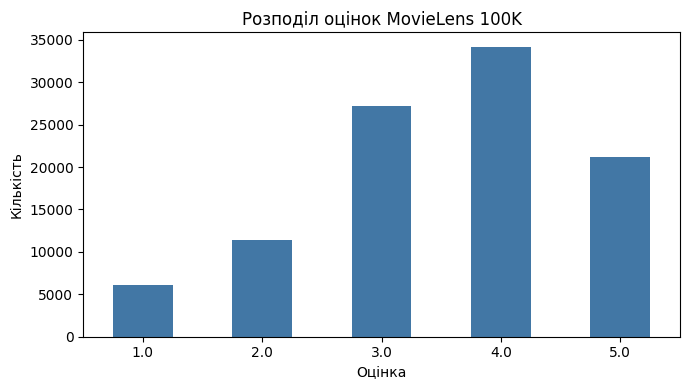

In [4]:
# 2.1. Опис набору даних та розподіл оцінок.
n_users = ratings_df['user_id'].nunique()
n_items = ratings_df['item_id'].nunique()
rating_min = ratings_df['rating'].min()
rating_max = ratings_df['rating'].max()
rating_mean = ratings_df['rating'].mean()
missing_values = ratings_df.isna().sum()

print(f'Кількість оцінок: {len(ratings_df):,}')
print(f'Унікальних користувачів: {n_users}')
print(f'Унікальних фільмів: {n_items}')
print(f'Оцінки: min={rating_min:.1f}, max={rating_max:.1f}, середня={rating_mean:.4f}')
print('Пропущені значення за колонками:')
display(missing_values.to_frame('Кількість пропусків'))

rating_distribution = ratings_df['rating'].value_counts().sort_index()
display(rating_distribution.rename_axis('rating').reset_index(name='count'))

import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
rating_distribution.plot.bar(color='#4277A5', rot=0)
plt.title('Розподіл оцінок MovieLens 100K')
plt.xlabel('Оцінка')
plt.ylabel('Кількість')
plt.tight_layout()
plt.show()


**Короткі спостереження щодо даних.** MovieLens 100K містить 100 000 оцінок від 943 користувачів для 1682 фільмів. Оцінки лежать у діапазоні від 1 до 5; середня оцінка становить приблизно 3,53, тобто користувачі частіше ставили помірно високі бали. Точні підрахунки, розподіл і перевірка пропусків наведені вище та перевіряються під час виконання.


## 3. Розбиття на навчальну та тестову вибірки

Виконайте випадкове розбиття **80% / 20%** із `random_state=42` за прикладом. Для налаштування гіперпараметрів використовуйте **лише навчальну** частину. Тестова вибірка має залишатися недоторканою до фінальної оцінки.

In [5]:
# 3.1. Незалежне тестове розбиття: 80% / 20%.
train_df, test_df = sklearn_train_test_split(
    ratings_df, test_size=0.2, random_state=42, shuffle=True
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f'Навчальних оцінок: {len(train_df)} ({len(train_df)/len(ratings_df):.0%})')
print(f'Тестових оцінок: {len(test_df)} ({len(test_df)/len(ratings_df):.0%})')
assert set(train_df.index) == set(range(len(train_df)))
assert len(train_df) + len(test_df) == len(ratings_df)


Навчальних оцінок: 80000 (80%)
Тестових оцінок: 20000 (20%)


In [6]:
# 3.2. Перетворення лише train_df на Dataset для CV; test_df залишається окремо.
reader = Reader(rating_scale=data.reader.rating_scale)
train_data = Dataset.load_from_df(
    train_df[['user_id', 'item_id', 'rating']], reader
)
testset = list(test_df[['user_id', 'item_id', 'rating']].itertuples(index=False, name=None))

assert len(testset) == len(test_df)
assert reader.rating_scale == (1, 5)
print('Шкала оцінок:', reader.rating_scale)
print('Кількість train / test:', len(train_df), '/', len(testset))
print('Перший тестовий запис:', testset[0])


Шкала оцінок: (1, 5)
Кількість train / test: 80000 / 20000
Перший тестовий запис: ('877', '381', 4.0)


## 4. Гіперпараметри моделей

Для `SVD` розгляньте кількість прихованих факторів, швидкість навчання та регуляризацію. Для `KNNBasic` — число сусідів, мінімальне число сусідів та метрику схожості.

Нижче — **початкова сітка** з аналізованого прикладу. Її можна змінити й обґрунтувати вибір.

In [7]:
# 8 конфігурацій SVD; 16 конфігурацій KNNBasic.
# Фіксуємо генератор випадкових чисел SVD; verbose=False прибирає зайві повідомлення.
param_grid_svd = {
    'n_factors': [50, 100],
    'lr_all': [0.005, 0.010],
    'reg_all': [0.02, 0.05],
    'random_state': [42]
}

param_grid_knn = {
    'k': [20, 40],
    'min_k': [1, 5],
    'sim_options': {
        'name': ['cosine', 'pearson'],
        'user_based': [False, True]
    },
    'verbose': [False]
}


**Обґрунтування параметрів.** У `SVD` кількість факторів `n_factors` (50 або 100) визначає розмір латентного представлення користувачів і фільмів, `lr_all` (0,005 або 0,01) — крок оптимізації, а `reg_all` (0,02 або 0,05) — силу регуляризації, що допомагає уникати перенавчання. Для `KNNBasic` значення `k` (20 або 40) задають найбільшу кількість сусідів, `min_k` (1 або 5) — мінімум потрібних сусідів; метрики `cosine` і `pearson` та підходи user-based/item-based дають змогу порівняти різні поняття схожості. Такі сітки невеликі, тому пошук здійсненний під час лабораторної; остаточний вибір проводиться **тільки за CV RMSE на навчальних даних**.


## 5. Пошук найкращих гіперпараметрів (GridSearchCV)

Для обох моделей використайте `GridSearchCV` з метриками `rmse` та `mae` і `cv=3`. Навчайте об’єкти пошуку **лише на `train_data`**.

In [8]:
# 5.1. Пошук параметрів SVD на навчальній вибірці (3 фолди).
# KFold з random_state фіксує випадкове розбиття в межах CV.
from surprise.model_selection import KFold

cv_splitter = KFold(n_splits=3, random_state=42, shuffle=True)
grid_search_svd = GridSearchCV(
    SVD, param_grid_svd,
    measures=['rmse', 'mae'], cv=cv_splitter, n_jobs=2
)
grid_search_svd.fit(train_data)
print('Пошук SVD завершено.')


Пошук SVD завершено.


In [9]:
# 5.2. Пошук KNNBasic на тих самих навчальних даних і з такими самими фолдами.
grid_search_knn = GridSearchCV(
    KNNBasic, param_grid_knn,
    measures=['rmse', 'mae'], cv=cv_splitter, n_jobs=2
)
grid_search_knn.fit(train_data)
print('Пошук KNNBasic завершено.')


Пошук KNNBasic завершено.


In [10]:
# 5.3. Показники для *однієї й тієї самої конфігурації*, найкращої за CV RMSE.
# Так не змішуємо мінімальний RMSE одних параметрів з мінімальним MAE інших.
def cv_rmse_summary(search, model_name):
    best_idx = int(np.argmin(search.cv_results['mean_test_rmse']))
    return {
        'Model': model_name,
        'CV RMSE': float(search.cv_results['mean_test_rmse'][best_idx]),
        'CV MAE': float(search.cv_results['mean_test_mae'][best_idx]),
        'Параметри (мін. RMSE)': search.best_params['rmse']
    }

cv_results = pd.DataFrame([
    cv_rmse_summary(grid_search_svd, 'SVD'),
    cv_rmse_summary(grid_search_knn, 'KNNBasic')
])
print('Найкращі результати кросвалідації за RMSE:')
display(cv_results)
for name, search in [('SVD', grid_search_svd), ('KNNBasic', grid_search_knn)]:
    print(f'\n{name}: найкращий CV RMSE={search.best_score["rmse"]:.4f}; '
          f'найкращий CV MAE={search.best_score["mae"]:.4f} '
          '(мінімум MAE може відповідати іншим гіперпараметрам)')
    print('Параметри за RMSE:', search.best_params['rmse'])
    print('Параметри за MAE:', search.best_params['mae'])


Найкращі результати кросвалідації за RMSE:


,Model,CV RMSE,CV MAE,Параметри (мін. RMSE)
0,SVD,0.942506,0.744138,"{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0..."
1,KNNBasic,1.027193,0.814330,"{'k': 40, 'min_k': 1, 'sim_options': {'name': ..."



SVD: найкращий CV RMSE=0.9425; найкращий CV MAE=0.7441 (мінімум MAE може відповідати іншим гіперпараметрам)
Параметри за RMSE: {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}
Параметри за MAE: {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}

KNNBasic: найкращий CV RMSE=1.0272; найкращий CV MAE=0.8143 (мінімум MAE може відповідати іншим гіперпараметрам)
Параметри за RMSE: {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}, 'verbose': False}
Параметри за MAE: {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}, 'verbose': False}


**Аналіз результатів кросвалідації.** Фактична таблиця `cv_results` (CV RMSE, CV MAE та оптимальні гіперпараметри) формується попередньою коміркою. Менше значення RMSE означає точніший прогноз рейтингу з більшим штрафом за великі помилки. Для фінального навчання обираємо гіперпараметри за **мінімальним CV RMSE**; значення MAE у порівняльній таблиці належить до тієї самої конфігурації.


## 6. Навчання остаточних моделей

Побудуйте `trainset = train_data.build_full_trainset()`. Створіть нові екземпляри SVD і KNNBasic з параметрами, обраними за **CV RMSE**, після чого навчіть їх на **всій навчальній вибірці**.

In [11]:
# 6.1–6.3. Моделі з найкращими параметрами за CV RMSE.
best_svd_params = dict(grid_search_svd.best_params['rmse'])
best_svd_params['random_state'] = 42
best_knn_params = dict(grid_search_knn.best_params['rmse'])

trainset = train_data.build_full_trainset()
best_svd = SVD(**best_svd_params)
best_knn = KNNBasic(**best_knn_params)
best_svd.fit(trainset)
best_knn.fit(trainset)

print(f'Навчено на {trainset.n_ratings} оцінках, '
      f'{trainset.n_users} користувачах, {trainset.n_items} фільмах.')
print('SVD:', best_svd_params)
print('KNNBasic:', best_knn_params)


Навчено на 80000 оцінках, 943 користувачах, 1653 фільмах.
SVD: {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}
KNNBasic: {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}, 'verbose': False}


## 7. Оцінювання на незалежній тестовій вибірці

Отримайте передбачення для `testset` методами `.test()` обох моделей. Обчисліть `RMSE` та `MAE` за допомогою `surprise.accuracy`.

**Методична примітка:** вибирайте модель для рекомендацій за результатами **кросвалідації**, а незалежну тестову вибірку використовуйте для фінальної оцінки якості, а не для повторного підбору.

In [12]:
# 7.1–7.2. Незалежний тест використовуємо один раз після підбору параметрів.
svd_predictions = best_svd.test(testset)
knn_predictions = best_knn.test(testset)

svd_rmse = accuracy.rmse(svd_predictions, verbose=False)
svd_mae = accuracy.mae(svd_predictions, verbose=False)
knn_rmse = accuracy.rmse(knn_predictions, verbose=False)
knn_mae = accuracy.mae(knn_predictions, verbose=False)

print(f'SVD:      Test RMSE={svd_rmse:.4f}, MAE={svd_mae:.4f}')
print(f'KNNBasic: Test RMSE={knn_rmse:.4f}, MAE={knn_mae:.4f}')


SVD:      Test RMSE=0.9192, MAE=0.7234
KNNBasic: Test RMSE=1.0120, MAE=0.7984


In [13]:
# 7.3. Порівняльна таблиця тестових результатів та відхилень від CV.
results = pd.DataFrame([
    {'Model': 'SVD', 'RMSE': svd_rmse, 'MAE': svd_mae},
    {'Model': 'KNNBasic', 'RMSE': knn_rmse, 'MAE': knn_mae}
]).sort_values(by='RMSE').reset_index(drop=True)

comparison = cv_results[['Model', 'CV RMSE', 'CV MAE']].merge(
    results.rename(columns={'RMSE': 'Test RMSE', 'MAE': 'Test MAE'}),
    on='Model'
)
comparison['Δ RMSE (Test − CV)'] = comparison['Test RMSE'] - comparison['CV RMSE']
comparison['Δ MAE (Test − CV)'] = comparison['Test MAE'] - comparison['CV MAE']

print('Результати на незалежній тестовій вибірці:')
display(results.round(4))
print('Порівняння CV і тестової вибірки:')
display(comparison.round(4))


Результати на незалежній тестовій вибірці:


,Model,RMSE,MAE
0,SVD,0.9192,0.7234
1,KNNBasic,1.0120,0.7984


Порівняння CV і тестової вибірки:


,Model,CV RMSE,CV MAE,Test RMSE,Test MAE,Δ RMSE (Test − CV),Δ MAE (Test − CV)
0,SVD,0.9425,0.7441,0.9192,0.7234,-0.0233,-0.0208
1,KNNBasic,1.0272,0.8143,1.0120,0.7984,-0.0152,-0.0159


**Таблиця тестових результатів та порівняння з CV** автоматично виводяться вище (`results` та `comparison`): там наведено RMSE, MAE й різницю між тестовими та CV-оцінками для кожної моделі. Невелика різниця свідчить про узгодженість оцінювання; більша можлива через зміну складу фолдів та незалежної тестової частини. **Важливо:** рішення про те, яку модель рекомендувати, ухвалюється за CV, а не за тестовою метрикою.


## 8. Топ-10 рекомендацій для користувача

1. Оберіть модель із кращим **CV RMSE**.
2. Задайте `user_id` (вихідний приклад використовує `'196'`).
3. Отримайте фільми, які цей користувач уже оцінив у навчальній вибірці.
4. Для решти фільмів обчисліть прогнозований рейтинг `.predict(uid=..., iid=...).est`.
5. Виведіть **10 фільмів із найбільшим прогнозованим рейтингом**.

**Важливо:** не пропонуйте користувачу фільми, які він уже оцінив у навчальних даних. Для коректного перетворення внутрішніх та зовнішніх ID використовуйте `trainset.to_inner_uid()`, `trainset.to_raw_iid()`.

In [14]:
# 8.1–8.4. Рекомендації від моделі з мінімальним CV RMSE.
from pathlib import Path

user_id = '196'  # raw ID користувача
selected_is_svd = (grid_search_svd.best_score['rmse'] <=
                   grid_search_knn.best_score['rmse'])
selected_model = best_svd if selected_is_svd else best_knn
selected_model_name = 'SVD' if selected_is_svd else 'KNNBasic'
print('Модель для рекомендацій (за CV RMSE):', selected_model_name)

def recommend_top_n(model, training_set, raw_user_id, n=10):
    try:
        inner_uid = training_set.to_inner_uid(str(raw_user_id))
    except ValueError:
        print(f'Користувача {raw_user_id!r} немає в навчальних даних. '
              'Потрібно обрати наявного користувача або реалізувати cold-start.')
        return pd.DataFrame(columns=['item_id', 'predicted_rating'])

    # trainset.ur[inner_uid] -> (внутрішній ID фільму, оцінка).
    already_rated_inner = {item_inner for item_inner, _ in training_set.ur[inner_uid]}
    candidates = [training_set.to_raw_iid(i) for i in range(training_set.n_items)
                  if i not in already_rated_inner]
    predicted = [(iid, model.predict(uid=str(raw_user_id), iid=iid).est)
                 for iid in candidates]
    top = pd.DataFrame(predicted, columns=['item_id', 'predicted_rating'])
    top = top.sort_values(['predicted_rating', 'item_id'],
                          ascending=[False, True]).head(n).reset_index(drop=True)
    assert not set(top['item_id']).intersection(
        {training_set.to_raw_iid(i) for i in already_rated_inner}
    )
    print(f'Користувач {raw_user_id}: оцінено у train {len(already_rated_inner)}; '
          f'неоцінених кандидатів {len(candidates)}.')
    return top

top10_df = recommend_top_n(selected_model, trainset, user_id, n=10)

# Необов'язково доповнюємо ID зрозумілими назвами з MovieLens u.item.
movie_info_path = Path.home() / '.surprise_data' / 'ml-100k' / 'ml-100k' / 'u.item'
if movie_info_path.exists() and not top10_df.empty:
    movie_titles = pd.read_csv(movie_info_path, sep='|', encoding='latin-1',
                               header=None, usecols=[0, 1])
    movie_titles.columns = ['item_id', 'title']
    movie_titles['item_id'] = movie_titles['item_id'].astype(str)
    top10_df = top10_df.merge(movie_titles, how='left', on='item_id')

print('Топ-10 рекомендованих фільмів:')
display(top10_df)


Модель для рекомендацій (за CV RMSE): SVD
Користувач 196: оцінено у train 29; неоцінених кандидатів 1624.
Топ-10 рекомендованих фільмів:


,item_id,predicted_rating,title
0,320,4.490358,Paradise Lost: The Child Murders at Robin Hood...
1,64,4.470680,"Shawshank Redemption, The (1994)"
2,480,4.413710,North by Northwest (1959)
3,313,4.401920,Titanic (1997)
4,513,4.399624,"Third Man, The (1949)"
5,483,4.398092,Casablanca (1942)
6,318,4.392102,Schindler's List (1993)
7,656,4.385379,M (1931)
8,22,4.377388,Braveheart (1995)
9,272,4.376010,Good Will Hunting (1997)


## 9. Контроль виконання

- [x] Передбачено завантаження та перевірку MovieLens 100K.
- [x] Реалізовано розбиття 80/20 з `random_state=42`.
- [x] Створено `Reader`, навчальний `Dataset` і тестові записи.
- [x] Реалізовано 3-fold `GridSearchCV` обох моделей **тільки на навчанні**.
- [x] Реалізовано виведення CV RMSE/MAE та підібраних параметрів.
- [x] Моделі перенавчаються на всіх 80% навчальних даних.
- [x] Реалізовано обчислення RMSE та MAE на незалежному тесті.
- [x] Порівняльні таблиці й пояснення створюються автоматично.
- [x] Топ-10 виключає фільми, оцінені користувачем у навчальних даних.
- [ ] Перевірити фактичне виконання всіх комірок у Google Colab (потрібні бібліотека `Surprise` і завантаження MovieLens).

**Порядок запуску:** у Google Colab оберіть **Runtime → Run all**. Якщо після встановлення пакетів Colab попросить перезавантажити сеанс, зробіть це та запустіть усі комірки повторно.


## 10. Додаткове завдання: власний рекомендаційний алгоритм з нуля

**Підхід:** user-based колаборативна фільтрація, реалізована за допомогою `NumPy` та `pandas` **без використання алгоритмів Surprise**. Для кожного користувача будуємо вектор оцінок, центруємо його відносно середньої оцінки користувача, рахуємо косинусну подібність між користувачами, зменшуємо ваги для пар із малим числом спільно оцінених фільмів і залишаємо не більш ніж `k=30` найближчих позитивно подібних сусідів, які оцінили потрібний фільм.

Оцінка для пари (користувач, фільм): середнє користувача + зважене середнє відхилень оцінок сусідів від їхніх середніх. Якщо відповідних сусідів немає, використовуємо середнє користувача і фільму; якщо користувач/фільм новий — доступні середні або глобальне середнє. **Додатковий алгоритм навчається виключно на `train_df`**, а тест використовується лише для оцінювання.


In [15]:
# Власна реалізація user-based CF на базі numpy; жодних Surprise SVD/KNN.
class UserBasedCF:
    def __init__(self, k=30, min_common=3, shrinkage=10.0):
        self.k = int(k)
        self.min_common = int(min_common)
        self.shrinkage = float(shrinkage)

    def fit(self, interactions):
        table = interactions[['user_id', 'item_id', 'rating']].copy()
        table['user_id'] = table['user_id'].astype(str)
        table['item_id'] = table['item_id'].astype(str)

        self.users_ = list(table['user_id'].unique())
        self.items_ = list(table['item_id'].unique())
        self.user_map_ = {uid: u for u, uid in enumerate(self.users_)}
        self.item_map_ = {iid: i for i, iid in enumerate(self.items_)}
        self.rating_matrix_ = np.zeros((len(self.users_), len(self.items_)), dtype=np.float32)

        for uid, iid, score in table.itertuples(index=False, name=None):
            self.rating_matrix_[self.user_map_[uid], self.item_map_[iid]] = float(score)

        self.rated_mask_ = self.rating_matrix_ > 0
        user_count = self.rated_mask_.sum(axis=1)
        item_count = self.rated_mask_.sum(axis=0)
        self.global_mean_ = float(table['rating'].mean())
        self.user_mean_ = self.rating_matrix_.sum(axis=1) / np.maximum(user_count, 1)
        self.item_mean_ = self.rating_matrix_.sum(axis=0) / np.maximum(item_count, 1)

        residuals = (self.rating_matrix_ - self.user_mean_[:, None]) * self.rated_mask_
        dot_products = residuals @ residuals.T
        norms = np.linalg.norm(residuals, axis=1)
        cosine = dot_products / np.maximum(norms[:, None] * norms[None, :], 1e-10)
        # Кількість оцінених обома користувачами фільмів.
        observed = self.rated_mask_.astype(np.float32)
        common = observed @ observed.T
        cosine *= common / (common + self.shrinkage)
        cosine[common < self.min_common] = 0.0
        np.fill_diagonal(cosine, 0.0)
        self.similarity_ = cosine
        return self

    def predict(self, user_id, item_id):
        uid, iid = str(user_id), str(item_id)
        u = self.user_map_.get(uid)
        i = self.item_map_.get(iid)
        if u is None and i is None:
            return self.global_mean_
        if u is None:
            return float(self.item_mean_[i])
        if i is None:
            return float(self.user_mean_[u])

        # Використовуємо тільки сусідів із позитивною подібністю та відомою оцінкою.
        possible = np.flatnonzero(self.rated_mask_[:, i] & (self.similarity_[u] > 0))
        if len(possible) == 0:
            score = 0.5 * (self.user_mean_[u] + self.item_mean_[i])
        else:
            if len(possible) > self.k:
                weights = self.similarity_[u, possible]
                possible = possible[np.argpartition(weights, -self.k)[-self.k:]]
            weights = self.similarity_[u, possible]
            deviations = self.rating_matrix_[possible, i] - self.user_mean_[possible]
            score = self.user_mean_[u] + np.dot(weights, deviations) / weights.sum()
        return float(np.clip(score, 1.0, 5.0))

    def recommend(self, user_id, n=10):
        uid = str(user_id)
        u = self.user_map_.get(uid)
        if u is None:
            return pd.DataFrame(columns=['item_id', 'predicted_rating'])
        candidate_indices = np.flatnonzero(~self.rated_mask_[u])
        scored = [(self.items_[i], self.predict(uid, self.items_[i]))
                  for i in candidate_indices]
        return (pd.DataFrame(scored, columns=['item_id', 'predicted_rating'])
                .sort_values(['predicted_rating', 'item_id'], ascending=[False, True])
                .head(n).reset_index(drop=True))


own_cf = UserBasedCF(k=30, min_common=3, shrinkage=10.0).fit(train_df)
print(f'Власна модель: {len(own_cf.users_)} користувачів, '
      f'{len(own_cf.items_)} фільмів, {len(train_df)} оцінок.')


Власна модель: 943 користувачів, 1653 фільмів, 80000 оцінок.


In [16]:
# Оцінка власного алгоритму на *тій самій* незалежній тестовій вибірці.
actual_ratings = test_df['rating'].to_numpy(dtype=float)
custom_predictions = np.array([
    own_cf.predict(uid, iid)
    for uid, iid in test_df[['user_id', 'item_id']].itertuples(index=False, name=None)
], dtype=float)
custom_rmse = float(np.sqrt(np.mean((actual_ratings - custom_predictions) ** 2)))
custom_mae = float(np.mean(np.abs(actual_ratings - custom_predictions)))

print(f'Власний user-based CF — Test RMSE: {custom_rmse:.4f}, MAE: {custom_mae:.4f}')
custom_top10 = own_cf.recommend(user_id, n=10)
if user_id in own_cf.user_map_:
    u = own_cf.user_map_[user_id]
    already_rated = {own_cf.items_[i] for i in np.flatnonzero(own_cf.rated_mask_[u])}
    assert not set(custom_top10['item_id']).intersection(already_rated)
print(f'Топ-10 власного алгоритму для користувача {user_id}:')
display(custom_top10)

print('Всі три підходи:')
display(pd.concat([
    results,
    pd.DataFrame([{'Model': 'Власний user-based CF',
                   'RMSE': custom_rmse, 'MAE': custom_mae}])
], ignore_index=True).sort_values('RMSE').round(4))


Власний user-based CF — Test RMSE: 0.9345, MAE: 0.7271
Топ-10 власного алгоритму для користувача 196:


,item_id,predicted_rating
0,1103,5.000000
1,1233,5.000000
2,1500,5.000000
3,1554,5.000000
4,1628,5.000000
5,1629,5.000000
6,1642,5.000000
7,1398,4.980296
8,1467,4.957341
9,1653,4.871921


Всі три підходи:


,Model,RMSE,MAE
0,SVD,0.9192,0.7234
2,Власний user-based CF,0.9345,0.7271
1,KNNBasic,1.0120,0.7984


## 11. Висновки

Нижче наведено автоматично сформульовані висновки з **фактично обчисленими** CV- і тестовими метриками, оптимальними параметрами, моделлю для рекомендацій та результатами власного алгоритму. Числа з’являться після запуску всіх комірок.

In [18]:
# Результат залежить від виконаного GridSearchCV — без вигаданих чисел.
from IPython.display import Markdown, display

cv_svd = float(grid_search_svd.best_score['rmse'])
cv_knn = float(grid_search_knn.best_score['rmse'])
selected_rmse = cv_svd if selected_is_svd else cv_knn
svd_delta = svd_rmse - cv_svd
knn_delta = knn_rmse - cv_knn

conclusion = (
    f'1. У роботі використано MovieLens 100K: {len(ratings_df):,} оцінок, '
    f'{n_users} користувачів і {n_items} фільмів.  '
    f'\n2. За перехресною перевіркою (3 фолди) SVD отримала RMSE={cv_svd:.4f}, '
    f'а KNNBasic — RMSE={cv_knn:.4f}; для рекомендацій обрано **{selected_model_name}**, '
    f'оскільки його CV RMSE нижчий ({selected_rmse:.4f}).  '
    f'\n3. Найкращі параметри SVD: `{best_svd_params}`.  '
    f'\n4. Найкращі параметри KNNBasic: `{best_knn_params}`.  '
    f'\n5. На незалежній тестовій вибірці для SVD: RMSE={svd_rmse:.4f}, '
    f'MAE={svd_mae:.4f}; для KNNBasic: RMSE={knn_rmse:.4f}, MAE={knn_mae:.4f}.  '
    f'\n6. Відхилення тестового RMSE від CV RMSE становить '
    f'{svd_delta:+.4f} для SVD та {knn_delta:+.4f} для KNNBasic; '
    f'це показує, наскільки оцінки на незалежних даних збігаються з CV.  '
    f'\n7. Власний алгоритм user-based CF із нуля дав на тесті RMSE={custom_rmse:.4f} '
    f'і MAE={custom_mae:.4f}, а топ-10 рекомендацій для користувача `{user_id}` '
    f'не містить фільмів, оцінених ним у навчальній вибірці.  '
    f'\n8. Основні обмеження: нові користувачі/фільми (cold-start), '
    f'розрідженість матриці оцінок і відсутність даних про жанри або зміст фільмів.'
)
display(Markdown(conclusion))


1. У роботі використано MovieLens 100K: 100,000 оцінок, 943 користувачів і 1682 фільмів.  
2. За перехресною перевіркою (3 фолди) SVD отримала RMSE=0.9425, а KNNBasic — RMSE=1.0272; для рекомендацій обрано **SVD**, оскільки його CV RMSE нижчий (0.9425).  
3. Найкращі параметри SVD: `{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}`.  
4. Найкращі параметри KNNBasic: `{'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}, 'verbose': False}`.  
5. На незалежній тестовій вибірці для SVD: RMSE=0.9192, MAE=0.7234; для KNNBasic: RMSE=1.0120, MAE=0.7984.  
6. Відхилення тестового RMSE від CV RMSE становить -0.0233 для SVD та -0.0152 для KNNBasic; це показує, наскільки оцінки на незалежних даних збігаються з CV.  
7. Власний алгоритм user-based CF із нуля дав на тесті RMSE=0.9345 і MAE=0.7271, а топ-10 рекомендацій для користувача `196` не містить фільмів, оцінених ним у навчальній вибірці.  
8. Основні обмеження: нові користувачі/фільми (cold-start), розрідженість матриці оцінок і відсутність даних про жанри або зміст фільмів.